# Exercise 58 – Classifying atoms from their local environment

**Week 11 · Classification**

Each atom in 1000 clusters carries a binary label. To predict it, every atom
is described by a 32-dimensional *radial descriptor*: a Gaussian-smeared
histogram of the distances to its neighbours. A small network maps the
descriptor to two logits (label `False` / `True`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from comphy import DATA_DIR
from comphy.clusters import plot_cluster
from comphy.descriptors import descriptor_grid, radial_descriptor
from comphy.models import MLP
from comphy.plotting import setup_axes
from comphy.training import train

torch.manual_seed(0)
rng = np.random.default_rng(0)

data = np.load(DATA_DIR / "clusters_with_atomic_labels.npz")
positions, labels = data["positions"], data["labels"]
print("positions:", positions.shape, " labels:", labels.shape)
print(f"fraction of atoms labelled True: {labels.mean():.2f}")

LABEL_COLORS = {False: "navy", True: "lightskyblue"}


def draw(ax, pos, lab, predicted=None):
    plot_cluster(ax, pos, color=[LABEL_COLORS[bool(l)] for l in lab], labels=False, size=250)
    if predicted is not None:
        p = pos[np.asarray(predicted, dtype=bool)]
        ax.scatter(p[:, 0], p[:, 1], marker="x", color="red", s=120, zorder=4)
    ax.set(xlim=(-4, 4), ylim=(-4, 4), xticks=[], yticks=[])

positions: (1000, 12, 2)  labels: (1000, 12)
fraction of atoms labelled True: 0.28


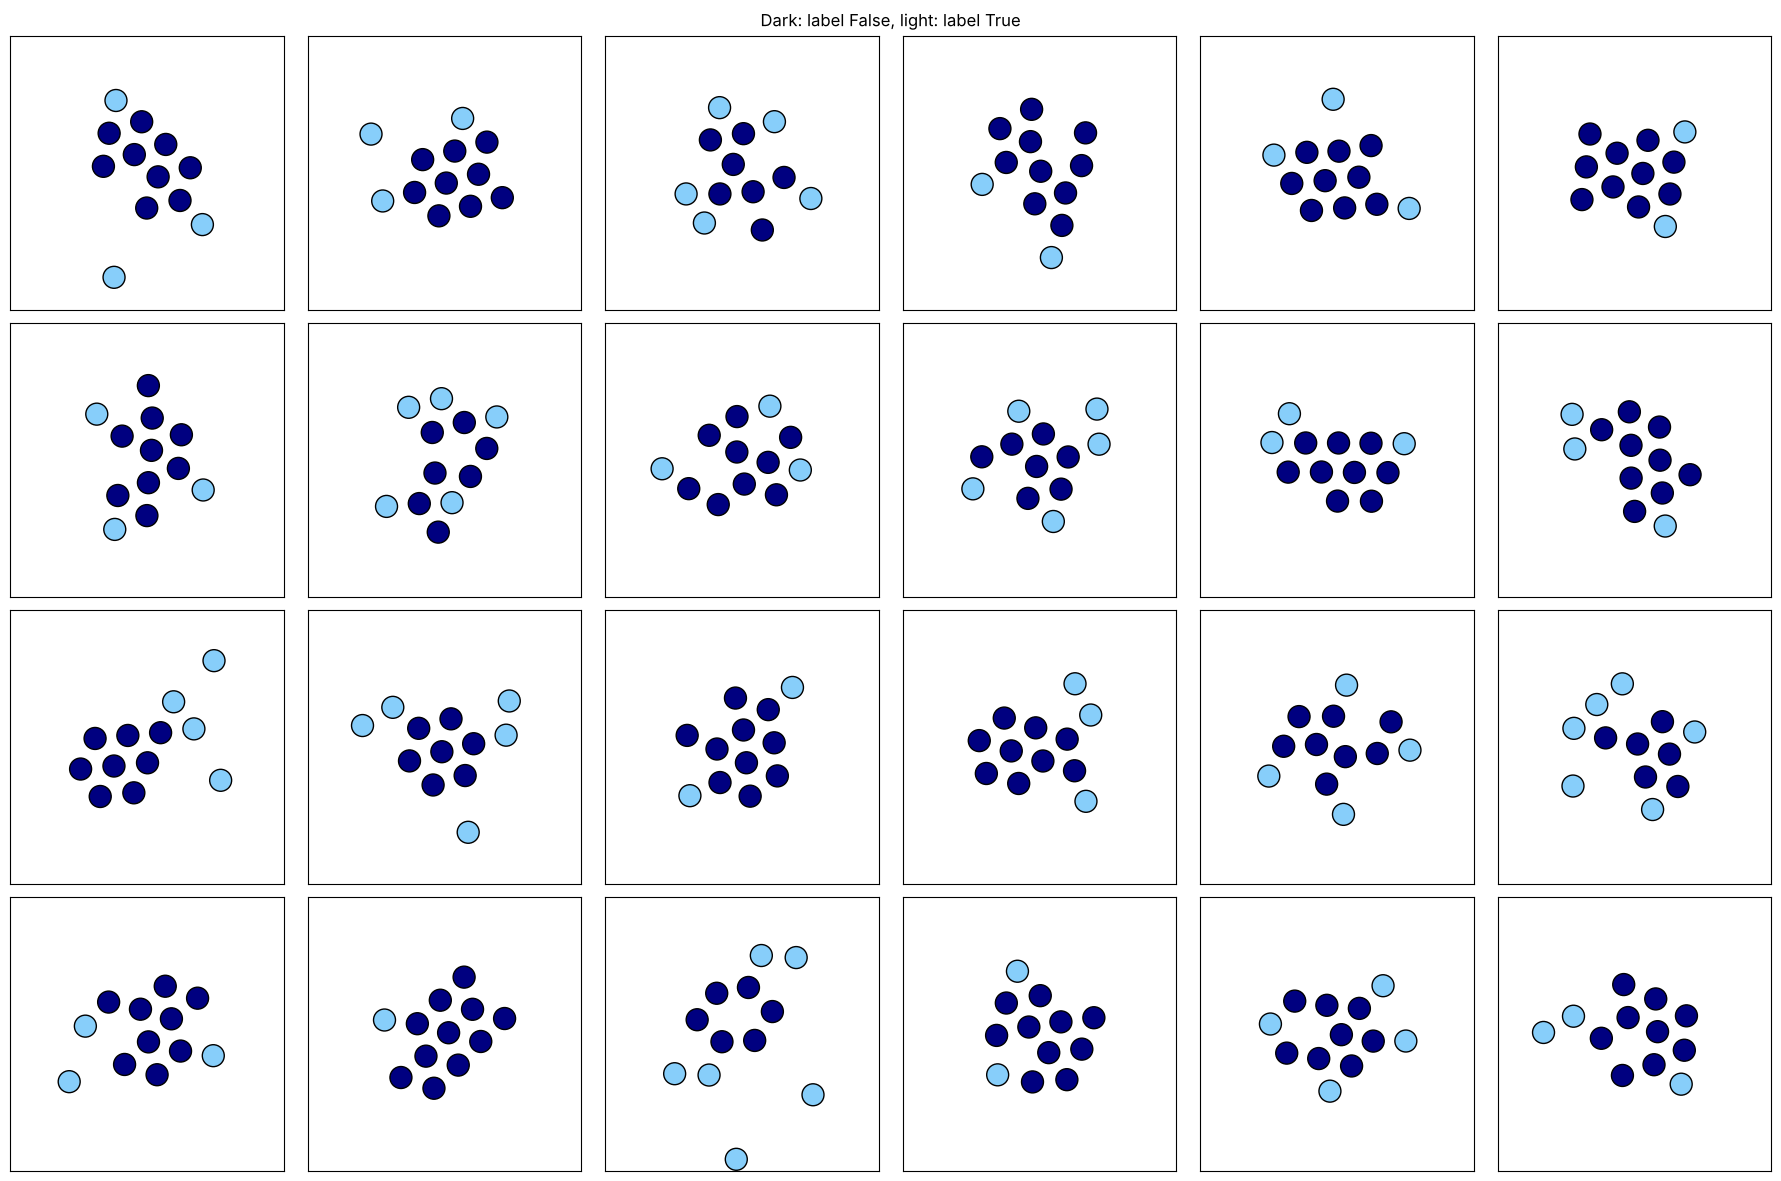

In [2]:
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for ax, pos, lab in zip(axes.flat, positions, labels):
    draw(ax, pos, lab)
fig.suptitle("Dark: label False, light: label True")
fig.tight_layout()
plt.show()

## The radial descriptor
Descriptors of the atoms in one cluster:

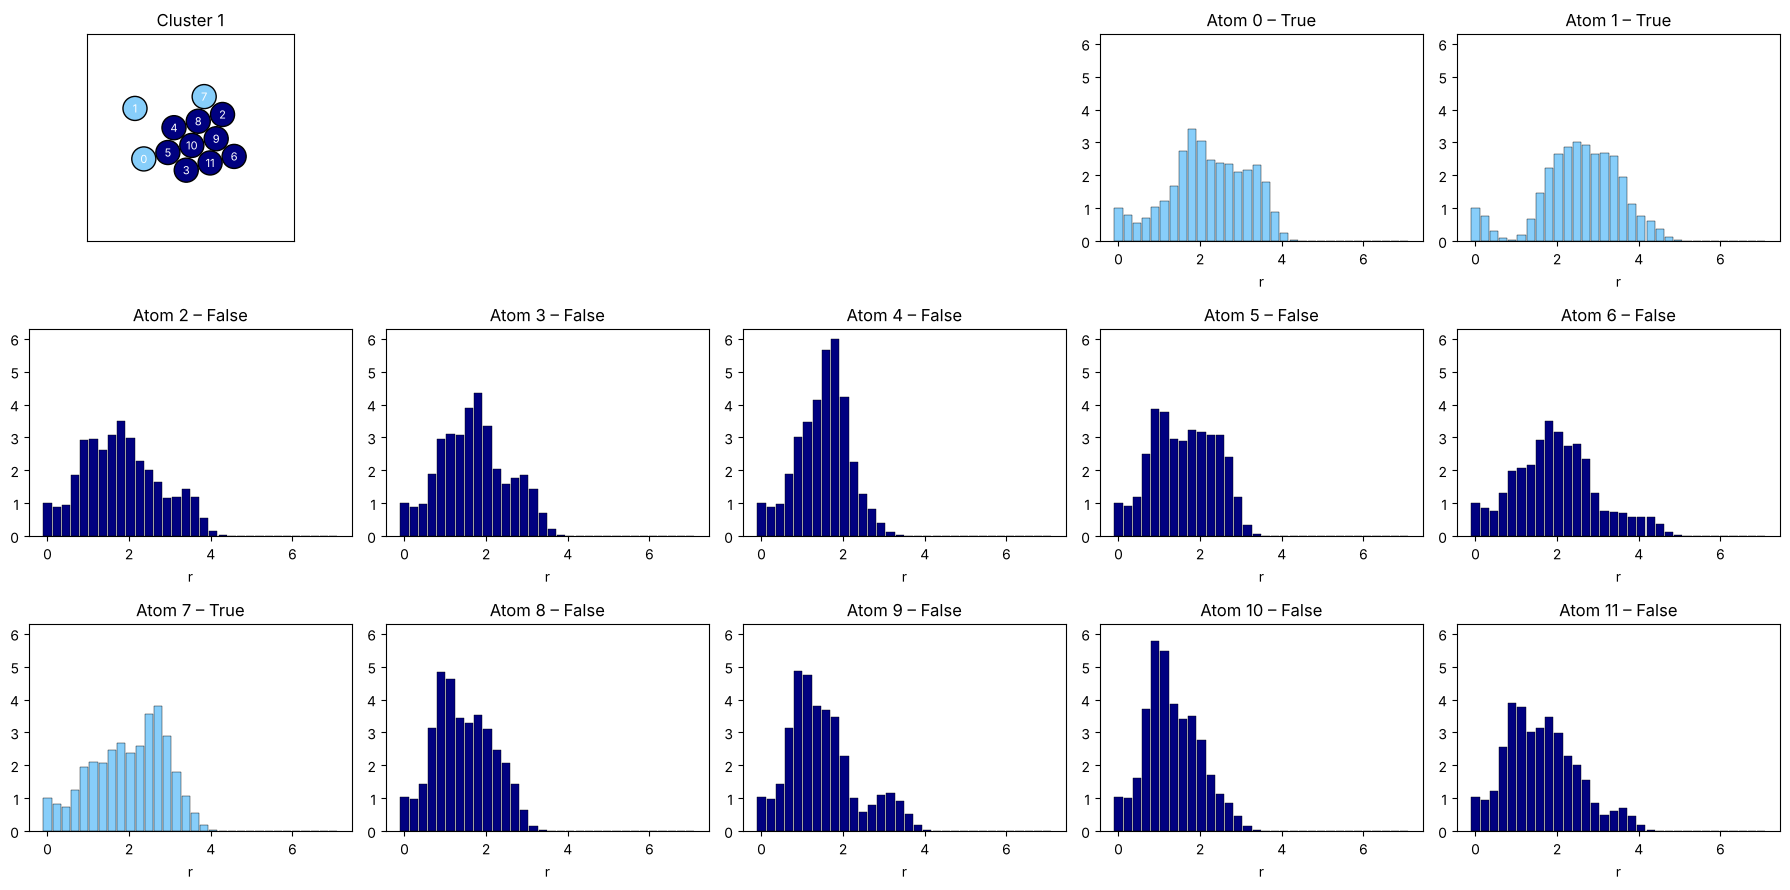

In [3]:
pos, lab = positions[1], labels[1]
descriptors = radial_descriptor(pos)
grid = descriptor_grid()

fig = plt.figure(figsize=(18, 9))
ax = fig.add_subplot(3, 5, 1)
plot_cluster(ax, pos, color=[LABEL_COLORS[bool(l)] for l in lab], size=300)
ax.set(xlim=(-4, 4), ylim=(-4, 4), xticks=[], yticks=[], title="Cluster 1")
for i, d in enumerate(descriptors):
    ax = fig.add_subplot(3, 5, i + 4)
    ax.bar(grid, d, width=0.2, color=LABEL_COLORS[bool(lab[i])], edgecolor="black", lw=0.3)
    ax.set(title=f"Atom {i} – {bool(lab[i])}", xlabel="r", ylim=(0, descriptors.max() * 1.05))
fig.tight_layout()
plt.show()

## Training the classifier

Clusters (not atoms) are split into training / validation / test sets, so
no test atom has neighbours in the training data. We train twice with
different amounts of training data.

In [4]:
all_descriptors = radial_descriptor(positions)          # (1000, 12, 32)
all_labels = torch.tensor(labels, dtype=torch.long)
loss_fn = nn.CrossEntropyLoss()


def split_indices(n, test_frac, val_frac):
    idx = rng.permutation(n)
    n_test, n_val = int(n * test_frac), int(n * val_frac)
    return idx[n_test + n_val:], idx[n_test:n_test + n_val], idx[:n_test]


def loader(idx, shuffle=False):
    X = all_descriptors[idx].reshape(-1, 32)
    y = all_labels[idx].reshape(-1)
    return DataLoader(TensorDataset(X, y), batch_size=32, shuffle=shuffle)


def confusion(model, idx):
    X = all_descriptors[idx].reshape(-1, 32)
    y = all_labels[idx].reshape(-1)
    with torch.no_grad():
        p = model.predict_label(X)
    return {"correct": (p == y).sum().item(),
            "false negatives": ((p == 0) & (y == 1)).sum().item(),
            "false positives": ((p == 1) & (y == 0)).sum().item()}


runs = {}
for test_frac in [0.1, 0.2]:
    train_idx, val_idx, test_idx = split_indices(len(positions), test_frac, 0.1)
    torch.manual_seed(0)
    model = MLP(n_in=32, n_out=2, hidden=(32, 32), activation="silu")
    history = train(model, loader(train_idx, shuffle=True), loader(val_idx), epochs=1000,
                    lr=1e-3, loss_fn=loss_fn, patience=50, restore_best=True)
    runs[test_frac] = dict(model=model, history=history, n_train=len(train_idx),
                           counts=confusion(model, test_idx))
    print(f"{len(train_idx)} training clusters -> test results {runs[test_frac]['counts']}")

Early stopping at epoch 205
800 training clusters -> test results {'correct': 1181, 'false negatives': 16, 'false positives': 3}


Early stopping at epoch 106
700 training clusters -> test results {'correct': 2358, 'false negatives': 15, 'false positives': 27}


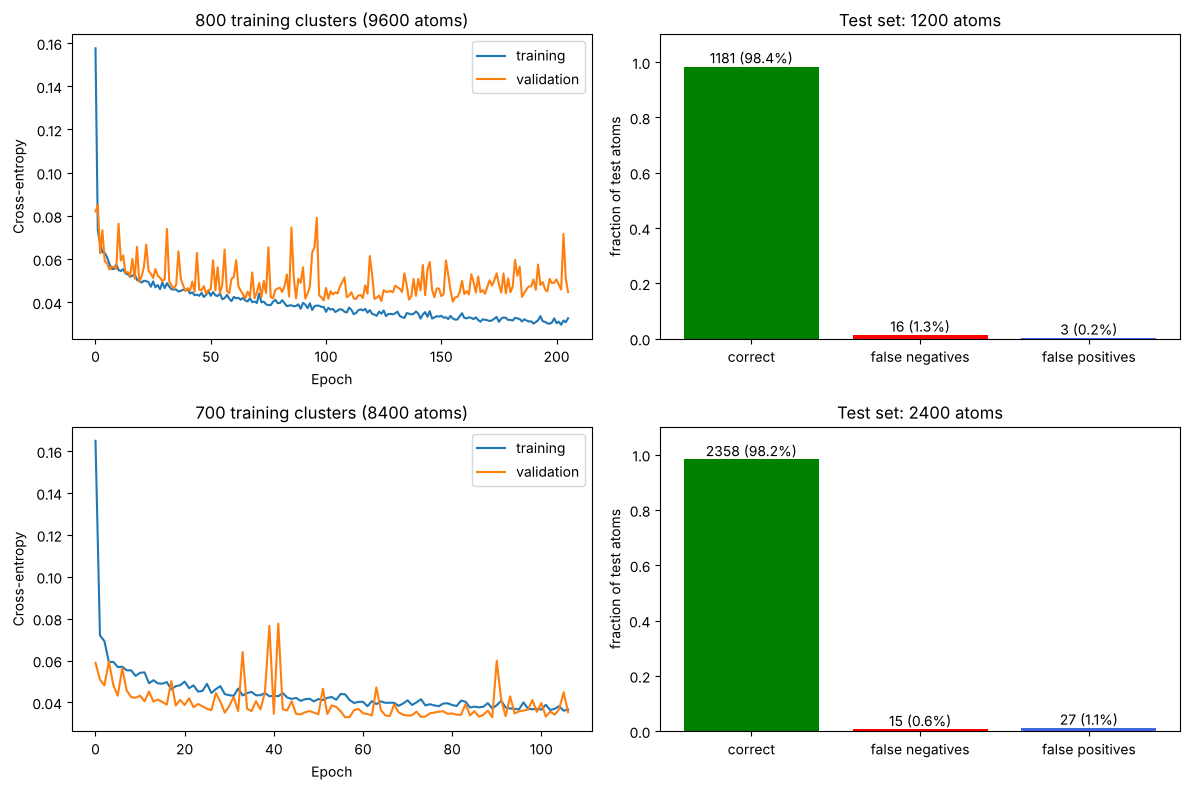

In [5]:
fig, axes = plt.subplots(len(runs), 2, figsize=(12, 4 * len(runs)))
for (ax_loss, ax_bar), run in zip(axes, runs.values()):
    ax_loss.plot(run["history"]["train"], label="training")
    ax_loss.plot(run["history"]["val"], label="validation")
    ax_loss.set(xlabel="Epoch", ylabel="Cross-entropy",
                title=f"{run['n_train']} training clusters ({run['n_train'] * 12} atoms)")
    ax_loss.legend()
    counts = run["counts"]
    total = sum(counts.values())
    bars = ax_bar.bar(list(counts), [c / total for c in counts.values()],
                      color=["green", "red", "royalblue"])
    ax_bar.bar_label(bars, labels=[f"{c} ({c / total:.1%})" for c in counts.values()])
    ax_bar.set(ylabel="fraction of test atoms", ylim=(0, 1.1), title=f"Test set: {total} atoms")
fig.tight_layout()
plt.show()

## Predictions on clusters
Red crosses mark atoms the model predicts to be `True`.

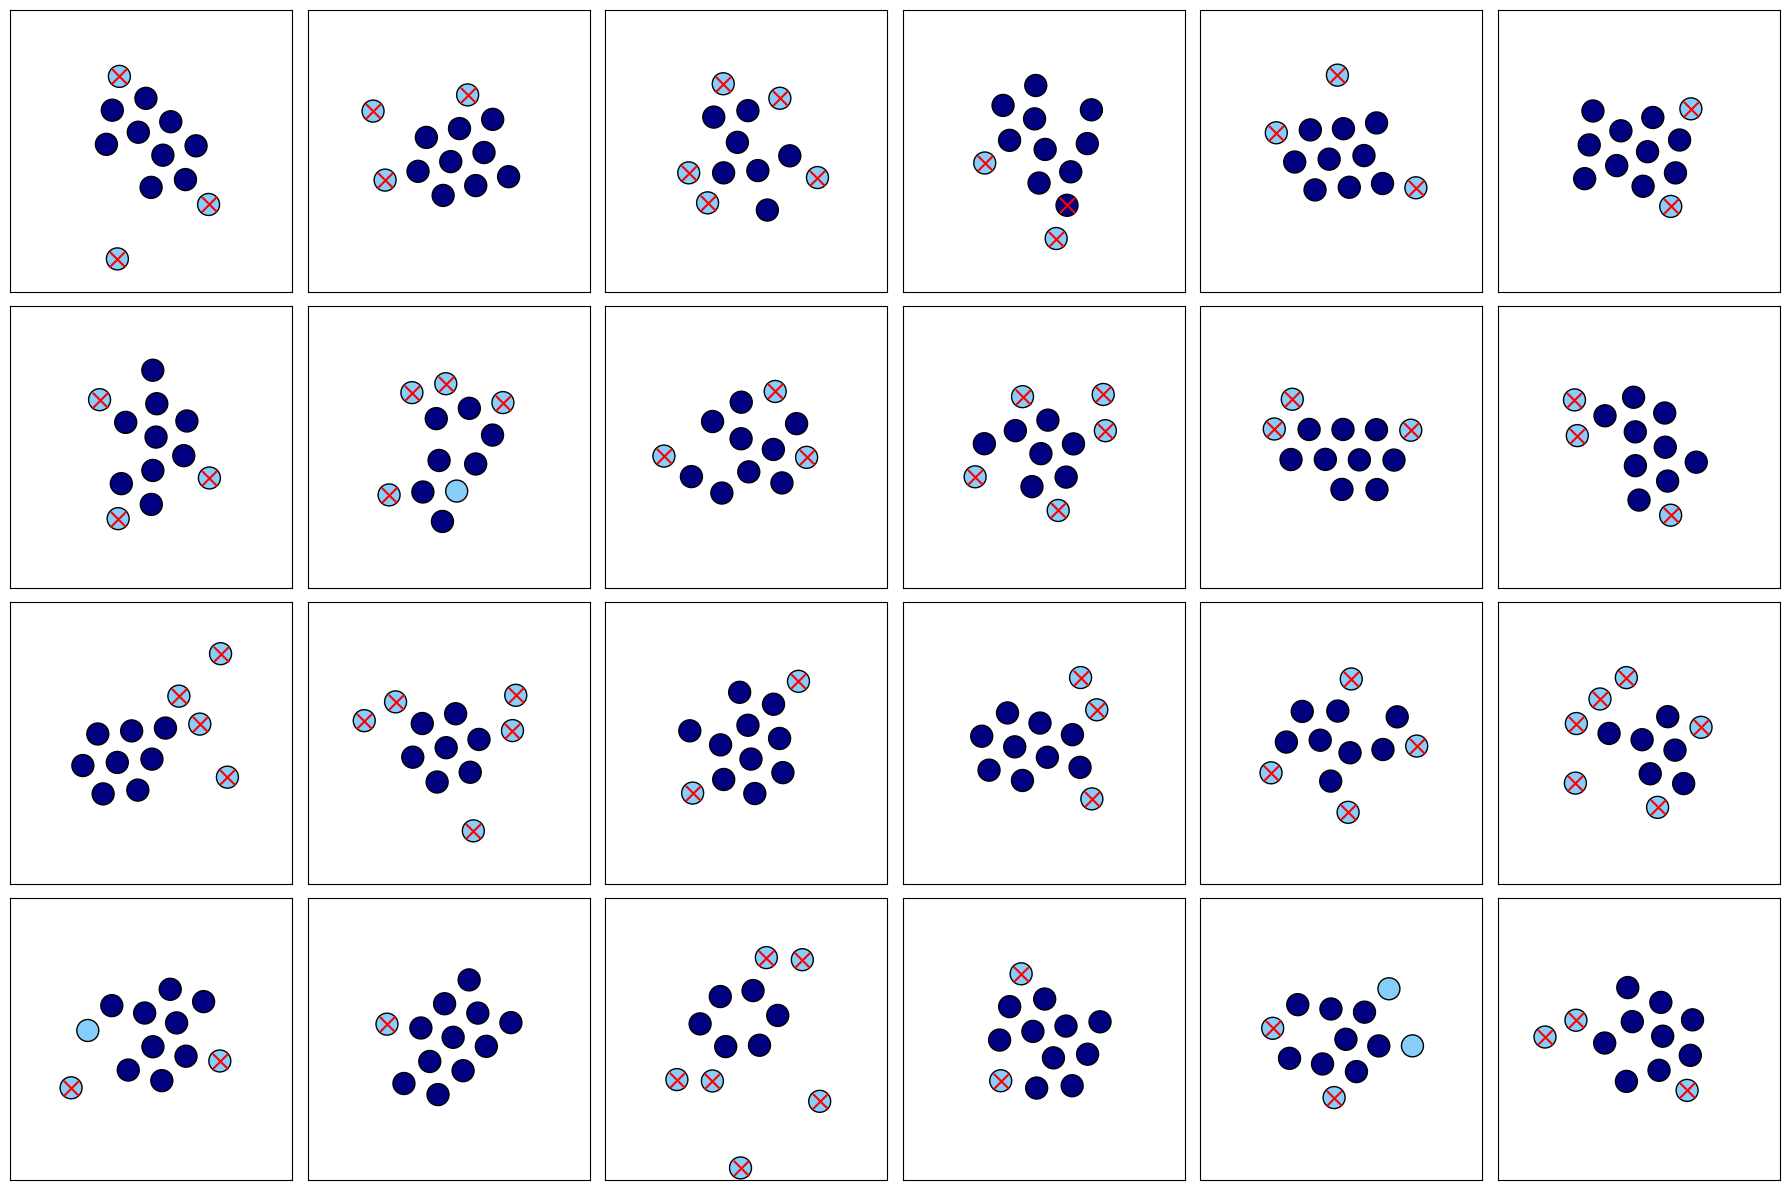

In [6]:
model = runs[0.1]["model"]
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for ax, pos, lab in zip(axes.flat, positions, labels):
    with torch.no_grad():
        predicted = model.predict_label(radial_descriptor(pos)).numpy()
    draw(ax, pos, lab, predicted)
fig.tight_layout()
plt.show()